<a href="https://colab.research.google.com/github/umar-akhtar-designer/1st-task/blob/main/Mini%20Machine%20Learning%20Model%20(Icodeguru).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
df = pd.read_csv("student_placement_data.csv")

df.head()

,cgpa,iq,10th_percentage,12th_percentage,communication_skills,projects_completed,placement
0,4.80,169.0,75.5,69.8,5.5,2,No
1,5.20,132.0,80.1,63.0,5.3,4,No
2,5.96,104.9,61.8,78.9,6.4,2,Yes
3,4.90,196.0,76.9,62.9,6.2,2,No
4,6.10,81.0,75.5,81.1,7.2,2,No


In [32]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 7)

Column Names:
['cgpa', 'iq', '10th_percentage', '12th_percentage', 'communication_skills', 'projects_completed', 'placement']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cgpa                  150 non-null    float64
 1   iq                    150 non-null    float64
 2   10th_percentage       150 non-null    float64
 3   12th_percentage       150 non-null    float64
 4   communication_skills  150 non-null    float64
 5   projects_completed    150 non-null    int64  
 6   placement             150 non-null    object 
dtypes: float64(5), int64(1), object(1)
memory usage: 8.3+ KB


In [33]:
print("Statistical Summary:")
display(df.describe())

print("\nFirst Five Records:")
display(df.head())

print("\nRandom Five Records:")
display(df.sample(5, random_state=42))

Statistical Summary:


,cgpa,iq,10th_percentage,12th_percentage,communication_skills,projects_completed
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,6.443000,118.762000,78.810667,77.543333,7.170667,2.786667
std,1.442254,34.821677,8.316153,9.851470,1.723293,1.770704
min,3.300000,37.000000,55.200000,58.200000,2.500000,0.000000
25%,5.202500,96.200000,74.125000,69.850000,5.925000,2.000000
50%,6.330000,120.000000,78.850000,78.050000,7.100000,2.000000
75%,7.352500,138.075000,84.475000,84.725000,8.300000,4.000000
max,9.790000,233.000000,99.000000,99.000000,10.000000,8.000000



First Five Records:


,cgpa,iq,10th_percentage,12th_percentage,communication_skills,projects_completed,placement
0,4.80,169.0,75.5,69.8,5.5,2,No
1,5.20,132.0,80.1,63.0,5.3,4,No
2,5.96,104.9,61.8,78.9,6.4,2,Yes
3,4.90,196.0,76.9,62.9,6.2,2,No
4,6.10,81.0,75.5,81.1,7.2,2,No



Random Five Records:


,cgpa,iq,10th_percentage,12th_percentage,communication_skills,projects_completed,placement
73,5.74,121.0,73.5,71.1,5.7,2,Yes
18,6.50,130.0,76.0,79.0,6.5,5,Yes
118,6.50,37.0,78.3,71.2,8.0,1,Yes
78,7.10,48.0,74.4,80.7,7.3,5,Yes
76,6.01,107.3,81.4,80.3,4.6,2,No


In [34]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
cgpa                    0
iq                      0
10th_percentage         0
12th_percentage         0
communication_skills    0
projects_completed      0
placement               0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0


placement
Yes    86
No     64
Name: count, dtype: int64


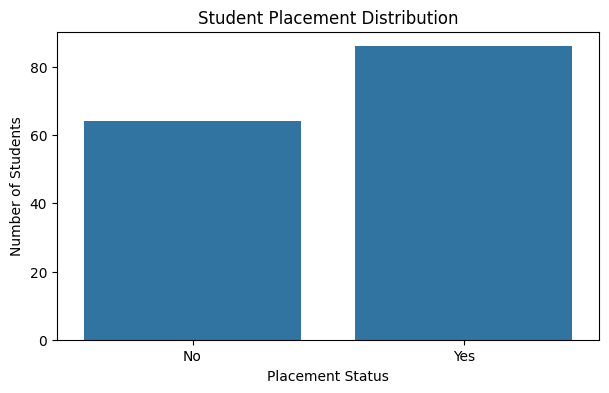

In [35]:
print(df["placement"].value_counts())

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="placement")

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

plt.show()

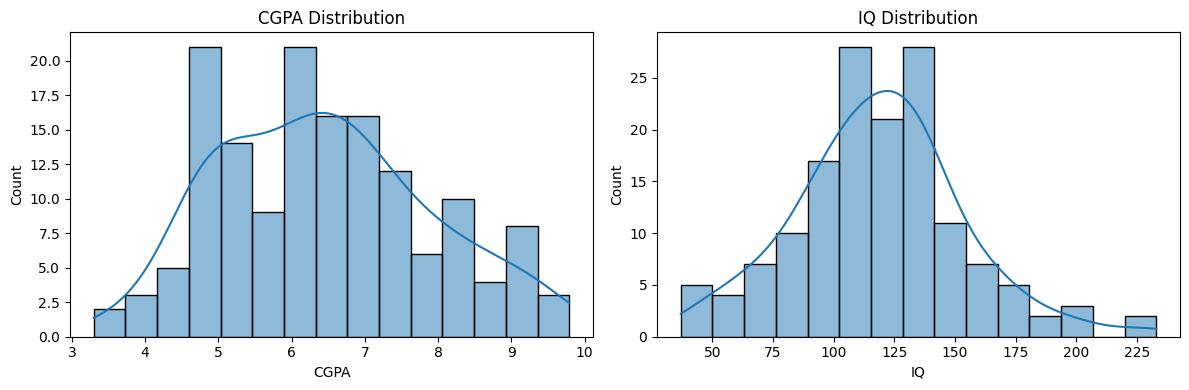

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["cgpa"], bins=15, kde=True, ax=axes[0])
axes[0].set_title("CGPA Distribution")
axes[0].set_xlabel("CGPA")

sns.histplot(df["iq"], bins=15, kde=True, ax=axes[1])
axes[1].set_title("IQ Distribution")
axes[1].set_xlabel("IQ")

plt.tight_layout()
plt.show()

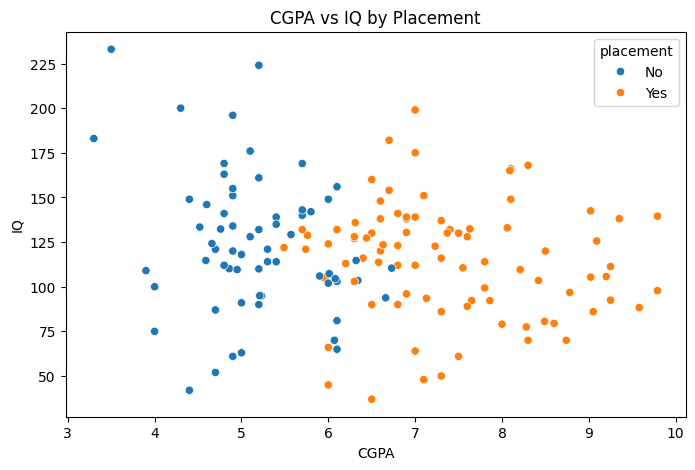

In [37]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="cgpa",
    y="iq",
    hue="placement"
)

plt.title("CGPA vs IQ by Placement")
plt.xlabel("CGPA")
plt.ylabel("IQ")

plt.show()

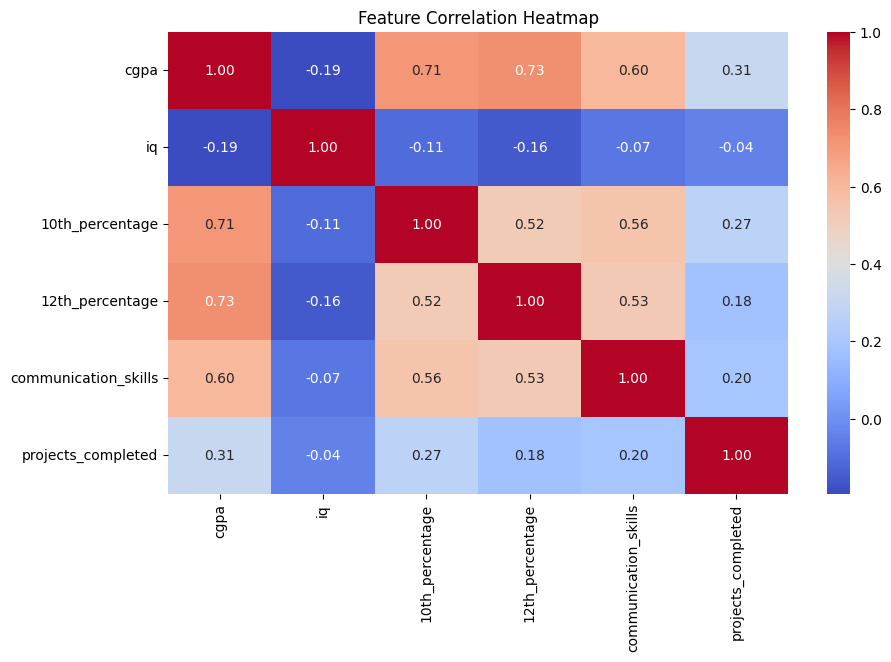

In [38]:
plt.figure(figsize=(10, 6))

correlation = df.drop(columns=["placement"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [39]:
df["placement"] = (
    df["placement"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

print(df["placement"].value_counts())

print("\nMissing target values:")
print(df["placement"].isnull().sum())

placement
1    86
0    64
Name: count, dtype: int64

Missing target values:
0


In [40]:
X = df[
    [
        "cgpa",
        "iq",
        "10th_percentage",
        "12th_percentage",
        "communication_skills",
        "projects_completed"
    ]
]

y = df["placement"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 6)
Target Shape: (150,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (120, 6)
Testing Features: (30, 6)
Training Labels: (120,)
Testing Labels: (30,)


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [43]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [44]:
y_pred = model.predict(X_test_scaled)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.to_numpy())

Predicted Values:
[1 0 1 0 1 1 0 0 1 1 0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 1 1 0]

Actual Values:
[1 0 1 0 1 1 0 0 1 1 0 0 0 1 1 0 1 0 1 0 0 1 0 0 1 1 1 1 1 1]


In [45]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Placed", "Placed"],
        zero_division=0
    )
)

Model Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.92      0.92      0.92        13
      Placed       0.94      0.94      0.94        17

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



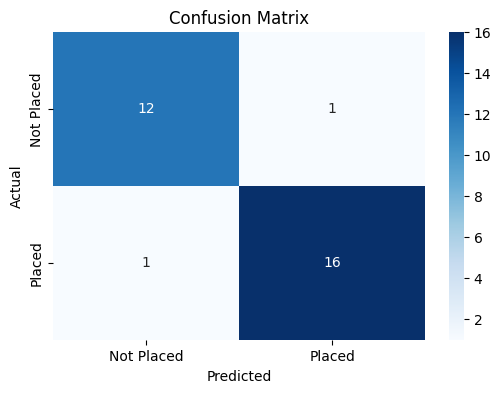

In [46]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [47]:
new_student = pd.DataFrame({
    "cgpa": [7.5],
    "iq": [120],
    "10th_percentage": [80],
    "12th_percentage": [82],
    "communication_skills": [8],
    "projects_completed": [3]
})

new_student_scaled = scaler.transform(new_student)

prediction = model.predict(new_student_scaled)[0]

probability = model.predict_proba(new_student_scaled)[0][1]

if prediction == 1:
    print("Prediction: Placed")
else:
    print("Prediction: Not Placed")

print(
    "Estimated Placement Probability:",
    round(probability * 100, 2),
    "%"
)

Prediction: Placed
Estimated Placement Probability: 97.53 %


In [48]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

display(
    coefficients.sort_values(
        by="Coefficient",
        ascending=False
    )
)

,Feature,Coefficient
0,cgpa,2.369200
4,communication_skills,1.282371
3,12th_percentage,0.493768
5,projects_completed,0.235726
1,iq,0.075571
2,10th_percentage,0.073727


In [49]:
import pickle
from google.colab import files

with open("placement_model.pkl", "wb") as file:
    pickle.dump(model, file)

with open("placement_scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Model and scaler saved successfully!")

files.download("placement_model.pkl")
files.download("placement_scaler.pkl")

Model and scaler saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>